<br>
<font>
<div dir=ltr align=center>
<img src="https://cdn.freebiesupply.com/logos/large/2x/sharif-logo-png-transparent.png" width=150 height=150> <br>
<font color=0F5298 size=7>
Artificial Intelligence <br>
<font color=2565AE size=5>
Computer Engineering Department <br>
Spring 2025<br>
<font color=3C99D size=5>
Practical Assignment 1 - Search <br>
<font color=696880 size=4>
Sadegh Mohammadian

____________

# Portfolio version

Implementation: **Behrad Mazaheri**. Based on the Sharif University of Technology Artificial Intelligence practical assignment (Spring 2025), credited to **Sadegh Mohammadian** in the original notebook. The maze, plotting helpers and fixed experiment configuration come from the assignment. Algorithm implementations and portfolio revisions are distinguished from those supplied components.

This edition corrects DFS accounting and bounded one-dimensional search, adds reproducible experiments and answers the analysis prompts. Student identifiers have been removed.


In [1]:
SEED = 42


# Rules
- Make sure that all of your cells can be run perfectly.
-Do not change the Parts which are not marked with #TODO
-Complete the functions or parts that are marked with #TODO
-Feel free to add functions if you need!.

# Search Algorithms
This notebook will guide you through the implementation of various search algorithms applied to a maze problem:
1. Depth-First Search (DFS)(10 points)
2. Breadth-First Search (BFS)(10 points)
3. A* Search(10 points)
4. Hill Climbing(25 points)
5. Genetic Algorithm(60points)

## Libraries

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from collections import deque
import math
import random

random.seed(SEED)
np.random.seed(SEED)


Let's define a simple maze structure to work with.

In [3]:
####################### Do not change ##############################
class Maze:
    def __init__(self, grid):
        self.grid = grid
        self.start = None
        self.goal = None

    def set_start(self, position):
        self.start = position

    def set_goal(self, position):
        self.goal = position

    def get_neighbors(self, position):
        neighbors = []
        x, y = position
        directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # Up, Down, Left, Right
        for dx, dy in directions:
            nx, ny = x + dx, y + dy
            if 0 <= nx < len(self.grid) and 0 <= ny < len(self.grid[0]) and self.grid[nx][ny] == 0:
                neighbors.append((nx, ny))
        return neighbors

    def visualize(self, path=[]):
        maze_copy = np.array(self.grid)
        for (x, y) in path:
            maze_copy[x][y] = 2  # Mark path
        plt.figure(figsize=(10, 10))
        plt.imshow(maze_copy, cmap="coolwarm")
        # Draw path by connecting the centers of squares
        
        if path:
            x_coords = [y  for (x, y) in path]
            y_coords = [x  for (x, y) in path]
            plt.plot(x_coords, y_coords, color="yellow", linewidth=2)
        if self.start:
            plt.scatter(self.start[1], self.start[0], color='black', s=100, label='Pacman')  # Pacman start
        if self.goal:
            plt.scatter(self.goal[1], self.goal[0], color='pink', s=100, label='Food')  # Food
        
        plt.xticks([])
        plt.yticks([])
        plt.show()
####################### Do not change ##############################

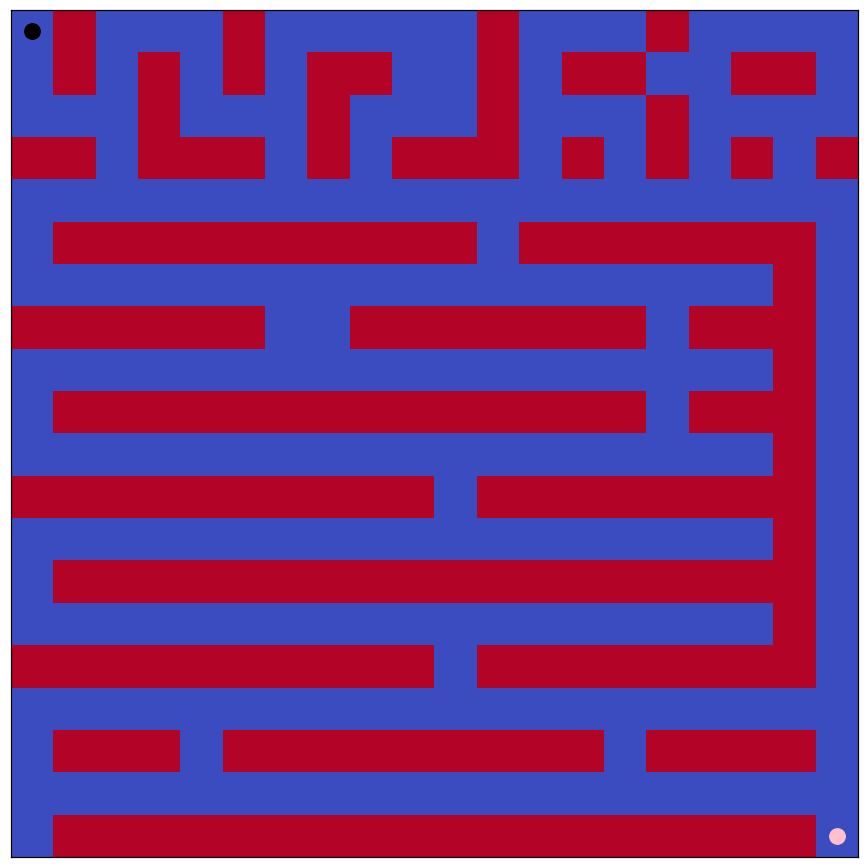

In [4]:

####################### Do not change ####################################
maze_grid = [
    [0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
    [0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0],
    [0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
    [1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
    [1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]
]

maze = Maze(maze_grid)
maze.set_start((0, 0))
maze.set_goal((19, 19))
maze.visualize()
####################### Do not change ####################################

In [5]:
def dfs(maze, start, goal):
    """Depth-first graph search; count all unique expanded states, including goal."""
    stack = [(start, [start])]
    visited = set()
    expanded = 0

    while stack:
        current, path = stack.pop()
        if current in visited:
            continue
        visited.add(current)
        expanded += 1
        if current == goal:
            return path, expanded
        # Reverse insertion preserves the maze's neighbor ordering.
        for neighbor in reversed(maze.get_neighbors(current)):
            if neighbor not in visited:
                stack.append((neighbor, path + [neighbor]))
    return [], expanded


DFS Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (2, 5), (2, 6), (1, 6), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (2, 8), (3, 8), (4, 8), (4, 7), (4, 6), (4, 5), (4, 4), (4, 3), (4, 2), (4, 1), (4, 0), (5, 0), (6, 0), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6), (7, 6), (8, 6), (8, 5), (8, 4), (8, 3), (8, 2), (8, 1), (8, 0), (9, 0), (10, 0), (10, 1), (10, 2), (10, 3), (10, 4), (10, 5), (10, 6), (10, 7), (10, 8), (10, 9), (10, 10), (11, 10), (12, 10), (12, 9), (12, 8), (12, 7), (12, 6), (12, 5), (12, 4), (12, 3), (12, 2), (12, 1), (12, 0), (13, 0), (14, 0), (14, 1), (14, 2), (14, 3), (14, 4), (14, 5), (14, 6), (14, 7), (14, 8), (14, 9), (14, 10), (15, 10), (16, 10), (16, 9), (16, 8), (16, 7), (16, 6), (16, 5), (16, 4), (17, 4), (18, 4), (18, 5), (18, 6), (18, 7), (18, 8), (18, 9), (18, 10), (18, 11), (18, 12), (18, 13), (18, 14), (17, 14), (16, 14), (16, 15), (16, 16), (16, 17), (16, 18), (16, 19), (17, 19), (18, 19), (19, 19)]

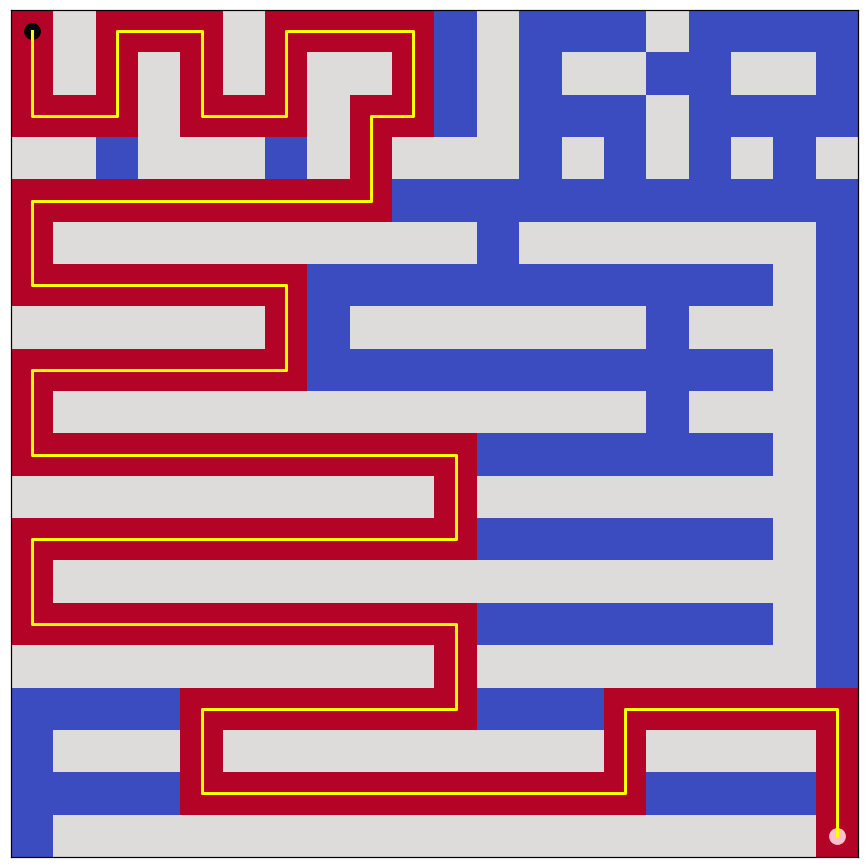

In [6]:
# Test DFS
result_dfs, expanded_nodes_dfs = dfs(maze, maze.start, maze.goal)
print("DFS Path:", result_dfs)
print("DFS Expanded Nodes:", expanded_nodes_dfs)
maze.visualize(result_dfs)

In [7]:
from collections import deque

def bfs(maze, start, goal):
    queue = deque()
    queue.append((start, [start]))
    visited = set()
    visited.add(start)
    expanded = []

    while queue:
        current, path = queue.popleft()
        expanded.append(current)

        if current == goal:
            return path, len(expanded)

        for neighbor in maze.get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append((neighbor, path + [neighbor]))

    return [], len(expanded)

BFS Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (4, 13), (4, 14), (4, 15), (4, 16), (4, 17), (4, 18), (4, 19), (5, 19), (6, 19), (7, 19), (8, 19), (9, 19), (10, 19), (11, 19), (12, 19), (13, 19), (14, 19), (15, 19), (16, 19), (17, 19), (18, 19), (19, 19)]
BFS Expanded Nodes: 161


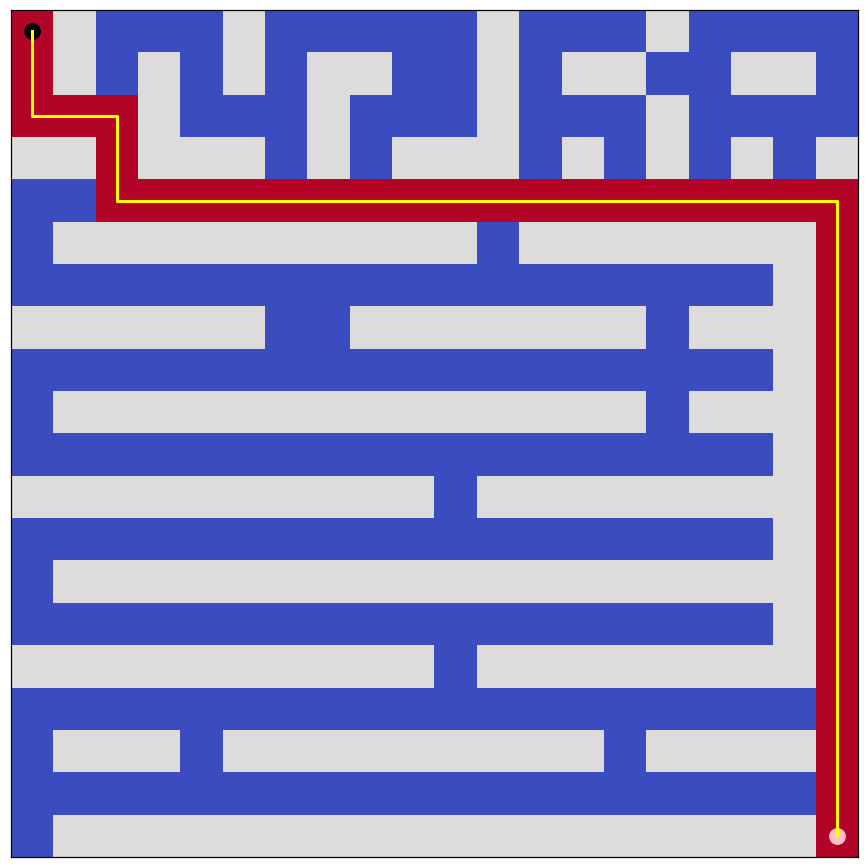

In [8]:
# Test BFS with expanded nodes
result_bfs, expanded_nodes_bfs = bfs(maze, maze.start, maze.goal)
print("BFS Path:", result_bfs)
print("BFS Expanded Nodes:", expanded_nodes_bfs)
maze.visualize(result_bfs)

In [9]:
def heuristic(a, b):
    """Manhattan distance for unit-cost, four-directional movement."""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

import heapq

def a_star(maze, start, goal):
    open_set = [(heuristic(start, goal), 0, start)]
    best_cost = {start: 0}
    parent = {start: None}
    closed = set()
    expanded = 0

    while open_set:
        _, cost, current = heapq.heappop(open_set)
        if current in closed or cost != best_cost[current]:
            continue
        closed.add(current)
        expanded += 1
        if current == goal:
            path = []
            while current is not None:
                path.append(current)
                current = parent[current]
            return path[::-1], expanded
        for neighbor in maze.get_neighbors(current):
            new_cost = cost + 1
            if new_cost < best_cost.get(neighbor, float('inf')):
                best_cost[neighbor] = new_cost
                parent[neighbor] = current
                heapq.heappush(open_set, (new_cost + heuristic(neighbor, goal), new_cost, neighbor))
    return [], expanded


A* Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (4, 13), (4, 14), (4, 15), (4, 16), (4, 17), (4, 18), (4, 19), (5, 19), (6, 19), (7, 19), (8, 19), (9, 19), (10, 19), (11, 19), (12, 19), (13, 19), (14, 19), (15, 19), (16, 19), (17, 19), (18, 19), (19, 19)]
A* Expanded Nodes: 55


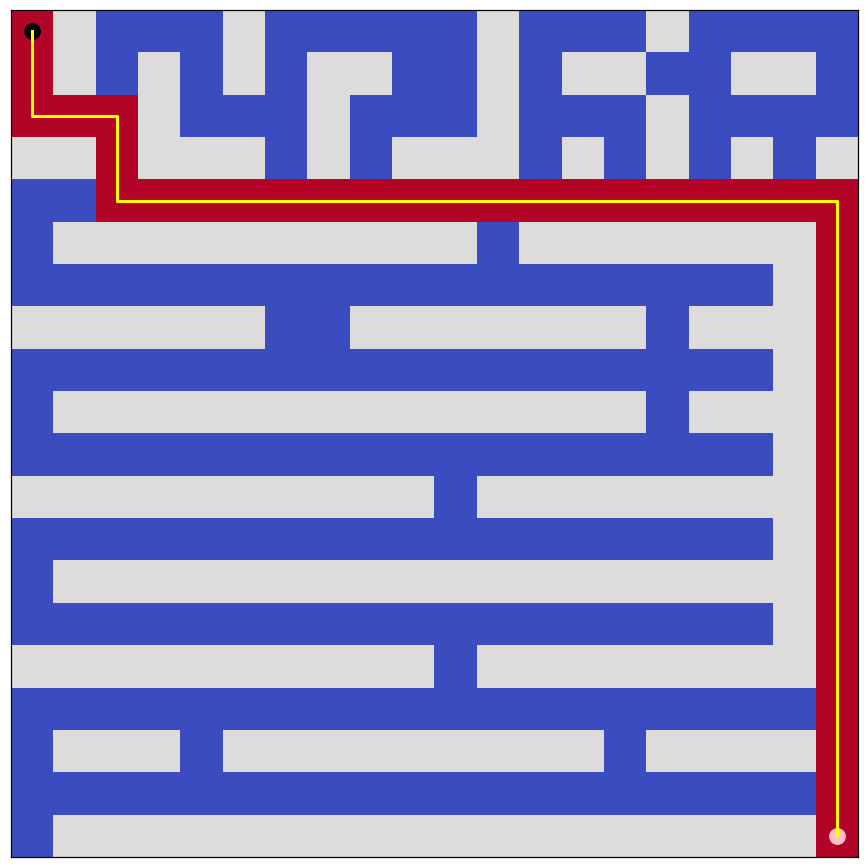

In [10]:
# Test A* with expanded nodes
result_a_star, expanded_nodes_a_star = a_star(maze, maze.start, maze.goal)
print("A* Path:", result_a_star)
print("A* Expanded Nodes:", expanded_nodes_a_star)
maze.visualize(result_a_star)

### Heuristic explanation

The heuristic is Manhattan distance: `abs(row - goal_row) + abs(col - goal_col)`. Movement is restricted to four directions, with unit cost per move. Ignoring walls cannot increase the estimated distance, so this is a lower bound on the remaining path length. Moving to an adjacent square changes this distance by at most one, making the heuristic consistent for this maze model. These properties support optimal A* search with the closed-set implementation used here.


In [11]:
def heuristic(a, b):  # Manhattan distance
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def hill_climbing(maze, start, goal):
    current = start
    path = [current]

    while current != goal:
        neighbors = maze.get_neighbors(current)
        neighbors = [n for n in neighbors if n not in path]

        if not neighbors:
            break

        next_node = min(neighbors, key=lambda n: heuristic(n, goal))

        if heuristic(next_node, goal) >= heuristic(current, goal):
            break

        current = next_node
        path.append(current)

    return path

Hill Climbing Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (5, 11), (6, 11), (6, 12), (6, 13), (6, 14), (6, 15), (7, 15), (8, 15), (9, 15), (10, 15), (10, 16), (10, 17)]


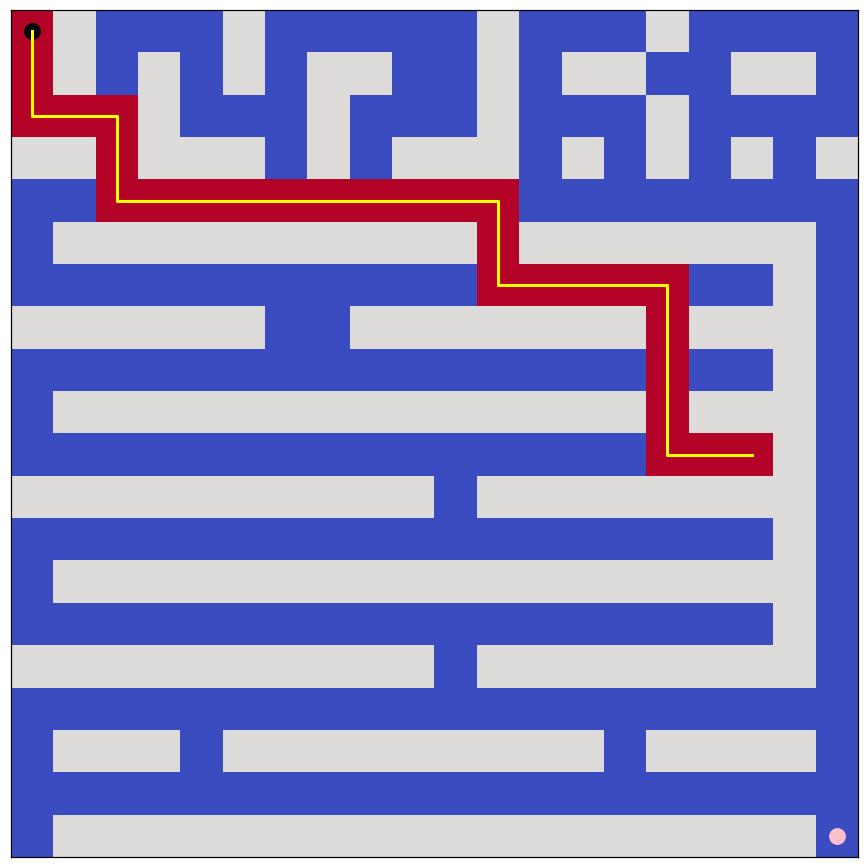

In [12]:
# Test Hill Climbing
result_hill_climbing = hill_climbing(maze, maze.start, maze.goal)
print("Hill Climbing Path:", result_hill_climbing)
maze.visualize(result_hill_climbing)

now implement the hill climbing algorithm with random moves and restarts

In [13]:
def hill_climbing_with_restart_random_move(maze, start, goal, max_restarts=20, p=0.1):
    for _ in range(max_restarts):
        current = start
        path = [current]

        while current != goal:
            neighbors = maze.get_neighbors(current)
            neighbors = [n for n in neighbors if n not in path]

            if not neighbors:
                break

            if random.random() < p:
                next_node = random.choice(neighbors)
            else:
                next_node = min(neighbors, key=lambda n: heuristic(n, goal))

                if heuristic(next_node, goal) >= heuristic(current, goal):
                    break

            current = next_node
            path.append(current)

        if current == goal:
            return path

    return []

Hill Climbing with Restart Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (4, 10), (4, 11), (4, 12), (4, 13), (4, 14), (4, 15), (4, 16), (4, 17), (4, 18), (4, 19), (5, 19), (6, 19), (7, 19), (8, 19), (9, 19), (10, 19), (11, 19), (12, 19), (13, 19), (14, 19), (15, 19), (16, 19), (17, 19), (18, 19), (19, 19)]


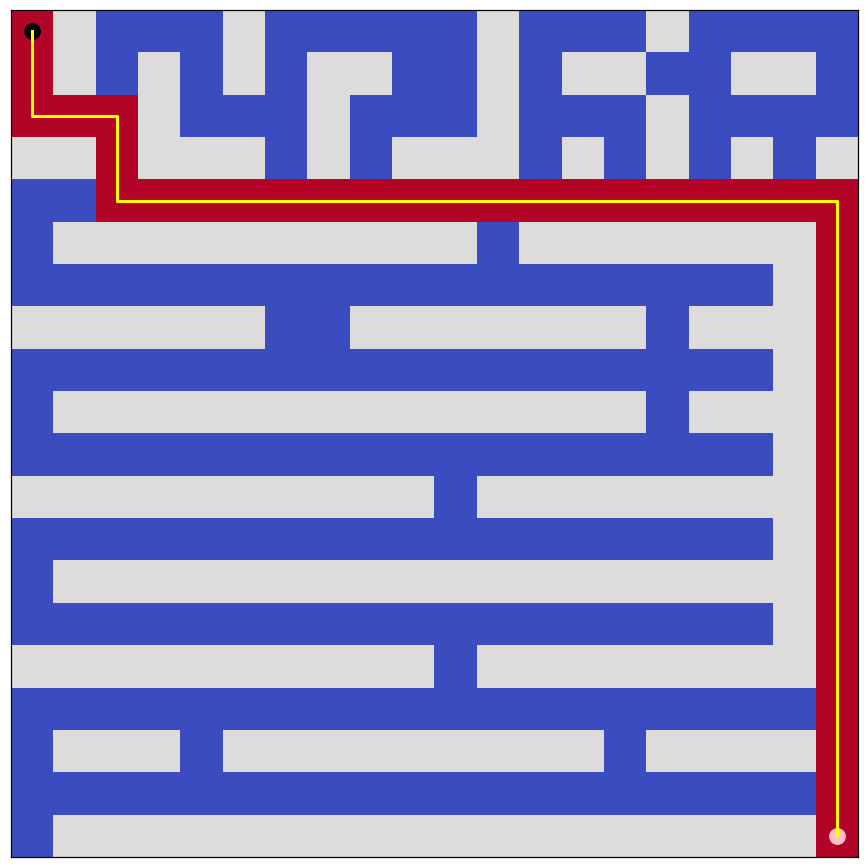

In [14]:
# Test Hill Climbing with Restart
result_hc_restart = hill_climbing_with_restart_random_move(maze, maze.start, maze.goal,p=0.2)
print("Hill Climbing with Restart Path:", result_hc_restart)
maze.visualize(result_hc_restart)

### Maze observations

BFS finds a shortest path because all moves have equal cost. DFS finds a valid route, but does not optimize its length. A* also finds a shortest path, while prioritizing states using the Manhattan lower bound. On the supplied maze, the original recorded BFS and A* runs used 38 moves and expanded 161 and 55 states respectively. The corrected runs are summarized at the end of this notebook; these counts are specific to the maze and neighbor/tie ordering.

Strict hill climbing stops at a local minimum: it cannot take a step that temporarily increases the Manhattan distance, even when that step is necessary to go around a wall. The randomized version occasionally permits such moves and retries from the same start. It may succeed, but does not guarantee success or a shortest path. Its failure is reported as an empty path rather than a successful solution.

The expansion convention counts every unique state removed for processing, including the goal. DFS now includes states explored in unsuccessful branches; the original copied branch counters did not measure total search effort.


# Part2 (Global minimum and Local minimum!)

in this part we want to find global minimum of function $f(x)$ in $[-2,2]$ with hill_climbing algorithm with random moves and restarts,our starting point is x=0.4:

$$f(x) = sin(3x) + 0.3x^2 - 0.7x ,    x \in [-2,2]$$

In [15]:
def f(x):
    return np.sin(3*x) + 0.3*x**2 - 0.7*x

complete `hill_climbing_1D_random` and run the code for 10 times and visualize the results with subplots

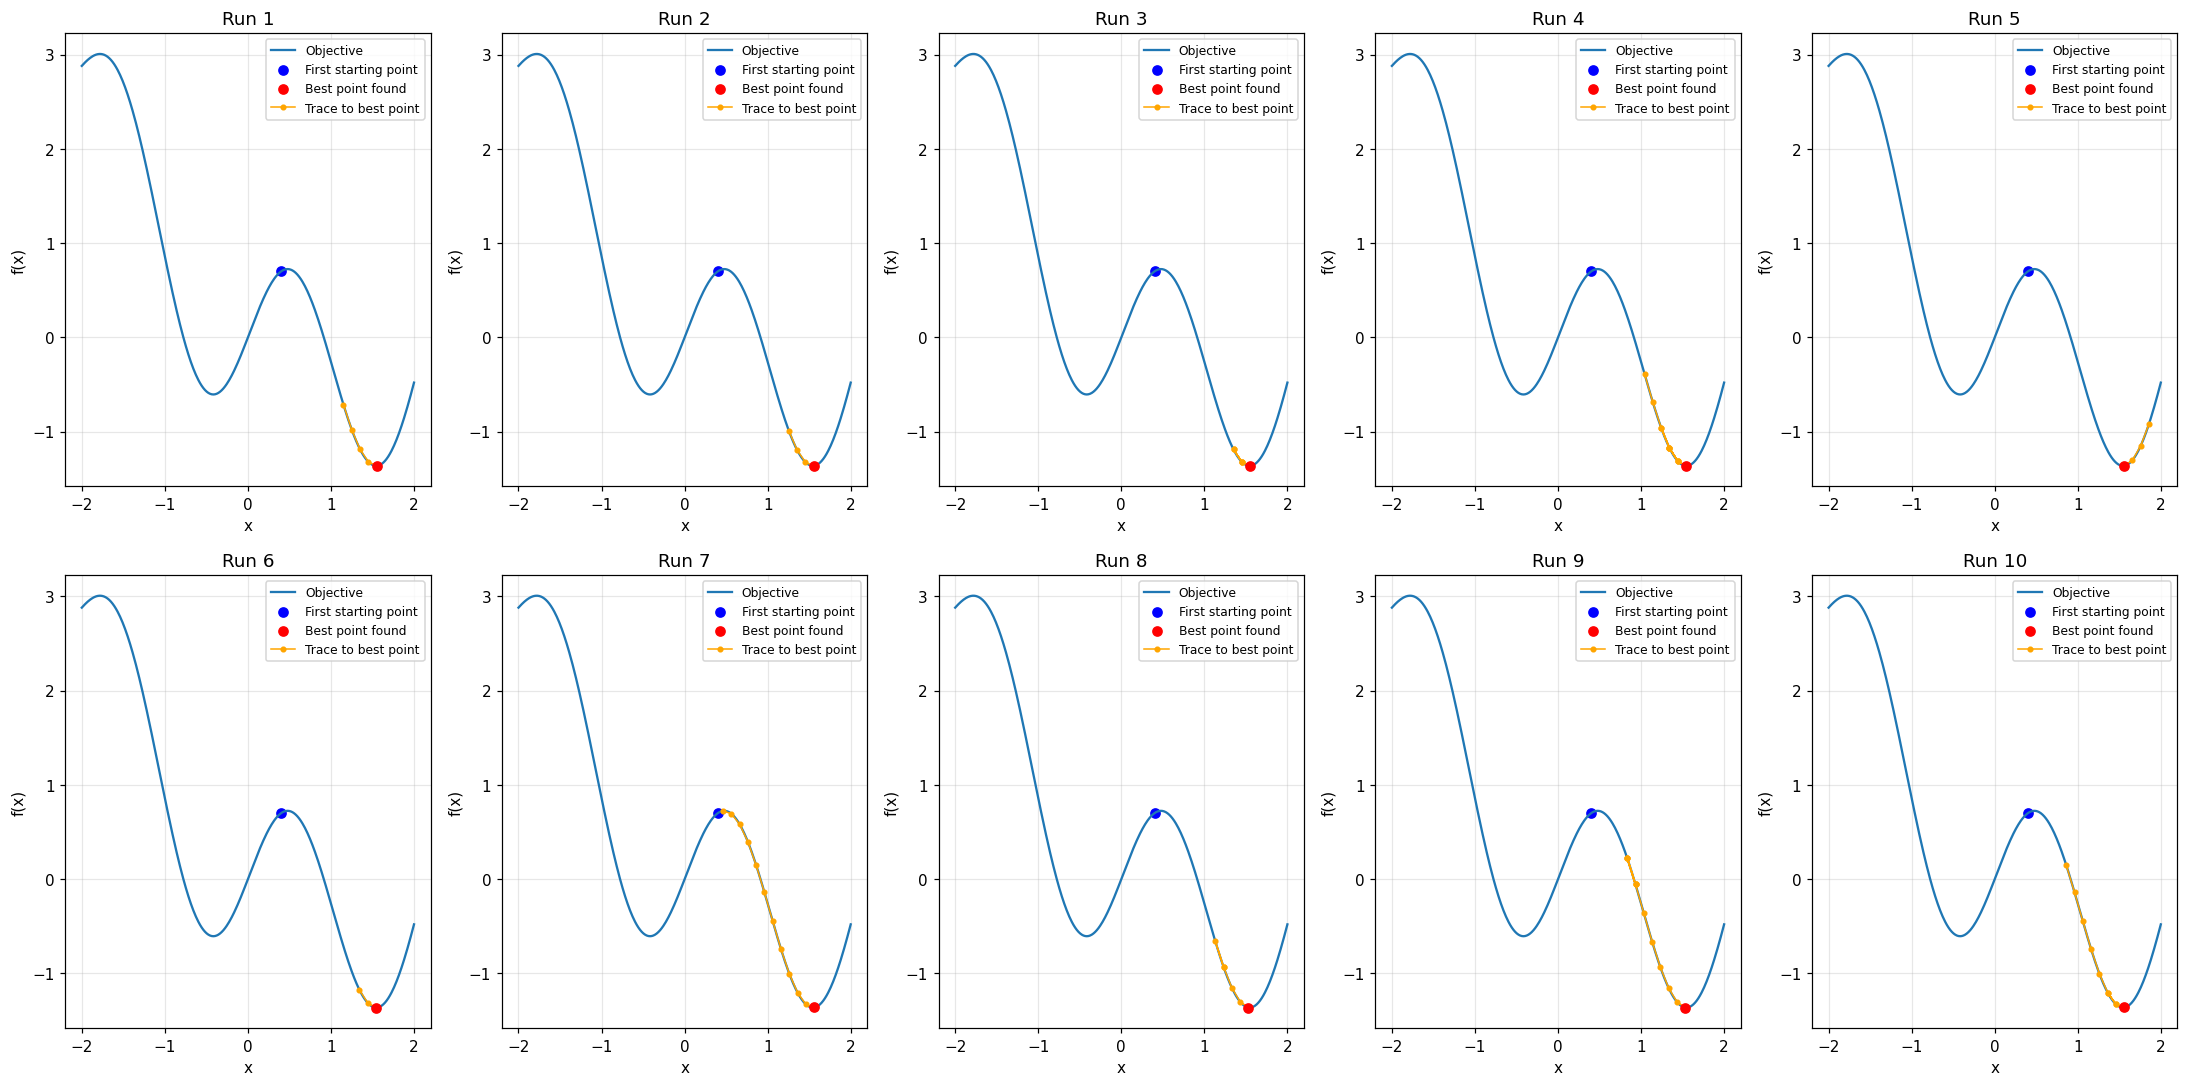

In [16]:
def hill_climbing_1D_random(f, x_start, step_size=0.1, max_iters=100,
                            p=0.2, bounds=(-2.0, 2.0), max_restarts=10):
    """Bounded stochastic descent; return the best visited point across restarts.

    The first attempt starts at x_start. Later attempts use random starts.
    The returned path belongs to the attempt containing the best point.
    """
    low, high = bounds
    if not low < high or not low <= x_start <= high:
        raise ValueError('Bounds must be ordered and contain x_start.')
    if step_size <= 0 or max_iters < 0 or max_restarts < 1 or not 0 <= p <= 1:
        raise ValueError('Invalid search parameters.')
    best_x, best_y = x_start, float(f(x_start))
    best_path = [x_start]
    for attempt in range(max_restarts):
        x = x_start if attempt == 0 else random.uniform(low, high)
        path = [x]
        if f(x) < best_y:
            best_x, best_y, best_path = x, float(f(x)), path.copy()
        for _ in range(max_iters):
            proposed = x + random.choice([-1, 1]) * step_size
            x_new = min(high, max(low, proposed))
            if x_new != x and (random.random() < p or f(x_new) < f(x)):
                x = x_new
                path.append(x)
                if f(x) < best_y:
                    best_x, best_y, best_path = x, float(f(x)), path.copy()
    return best_x, best_y, best_path

random.seed(SEED)
fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.flatten()
one_dimensional_results = []
x_start = 0.4  # Assignment-specified first starting point.
for i in range(10):
    x_vals = np.linspace(-2, 2, 400)
    x_opt, y_opt, path = hill_climbing_1D_random(f, x_start=x_start)
    one_dimensional_results.append({'run': i + 1, 'x': float(x_opt), 'f_x': float(y_opt)})
    axes[i].plot(x_vals, f(x_vals), label='Objective')
    axes[i].scatter(x_start, f(x_start), color='blue', label='First starting point')
    axes[i].scatter(x_opt, y_opt, color='red', zorder=3, label='Best point found')
    axes[i].plot(path, [f(x) for x in path], color='orange', marker='.',
                 linewidth=1, label='Trace to best point')
    axes[i].legend(fontsize=8)
    axes[i].set(xlabel='x', ylabel='f(x)', title=f'Run {i+1}')
    axes[i].grid(alpha=0.3)
plt.tight_layout()
plt.show()


### One-dimensional results

The objective has multiple local minima on `[-2, 2]`. Occasional uphill moves and random restarts increase exploration; they do not prove that the global minimum has been reached. This edition clips every proposed step to the interval, uses 10 attempts per run, and retains the best point visited rather than returning an arbitrary final random position. The first attempt starts at the required `0.4`; subsequent attempts use uniform random starts. Each subplot shows the attempt's trace up to its best point, which may start at a restart location.

A dense-grid reference and the ten achieved objective values are reported in the final summary. The grid is a numerical comparison, not an exact optimality certificate.


# Part3 (Genetic Algorithm)(60 points)

in this part we want to Solve TSP problem with Genetic algorithm

first read the list of cities and their cordinates from TSP51.txt file

In [17]:
from pathlib import Path

def getCity(filename='TSP51.txt'):
    """Read id, x, y rows from the supplied coordinate file."""
    path = Path(filename)
    if not path.is_file():
        raise FileNotFoundError(f'{path} not found. Run from the assignment directory.')
    cities = []
    with path.open(encoding='utf-8') as source:
        for line_number, line in enumerate(source, 1):
            if not line.strip():
                continue
            parts = line.split()
            if len(parts) != 3:
                raise ValueError(f'Expected id, x, y on line {line_number}.')
            city_id, x, y = parts
            cities.append((float(city_id), float(x), float(y)))
    if len(cities) < 2 or len({c[0] for c in cities}) != len(cities):
        raise ValueError('At least two cities with distinct identifiers are required.')
    return cities


In [18]:
# calculating distance of the cities
def calcDistance(cities):
    total_sum = 0
    for i in range(len(cities)):
        z1,x1, y1 = cities[i]
        z2,x2, y2 = cities[(i + 1) % len(cities)]
        total_sum += ((x1 - x2)**2 + (y1 - y2)**2)**0.5
    return total_sum

In [19]:
# selecting the population
def selectPopulation(cities, size):
    population = []
    for _ in range(size):
        temp = cities.copy()
        random.shuffle(temp)
        distance = calcDistance(temp)
        population.append((distance, temp))
    population.sort()
    fitest = population[0]
    return population, fitest

In [20]:
# the genetic algorithm
def geneticAlgorithm(
    population,
    lenCities,
    TOURNAMENT_SELECTION_SIZE,
    MUTATION_RATE,
    CROSSOVER_RATE,
    TARGET,
    ITERATION=200
):
    gen_number = 0
    for i in range(ITERATION):
        new_population = []

        # selecting two of the best options we have (elitism)
        population.sort()
        new_population.extend(population[:2])

        while len(new_population) < len(population):
            tournament = random.sample(population, TOURNAMENT_SELECTION_SIZE)
            tournament.sort()
            parent1 = tournament[0][1]
            parent2 = tournament[1][1]

            # CROSSOVER
            random_number = random.random()
            if random_number < CROSSOVER_RATE:
                cut = random.randint(0, lenCities - 1)
                child = parent1[:cut]
                child += [c for c in parent2 if c not in child]
            else:
                child = parent1.copy()

            # MUTATION
            if random.random() < MUTATION_RATE:
                idx1, idx2 = random.sample(range(lenCities), 2)
                child[idx1], child[idx2] = child[idx2], child[idx1]

            dist = calcDistance(child)
            new_population.append((dist, child))

        population = new_population
        gen_number += 1

        if gen_number % 10 == 0:
            print(gen_number, sorted(population)[0][0])

        if sorted(population)[0][0] < TARGET:
            break

    answer = sorted(population)[0]
    return answer, gen_number

In [21]:
# draw cities and answer map
##################### Do not change ###########################
def drawMap(city, answer):
     for j in city:
        plt.plot(j[1], j[2], "ro")
        plt.annotate(j[0], (j[1], j[2]))

     for i in range(len(answer[1])):
        try:
            first = answer[1][i]
            secend = answer[1][i + 1]

            plt.plot([first[1], secend[1]], [first[2], secend[2]], "gray")
        except:
            continue

     first = answer[1][0]
     secend = answer[1][-1]
     plt.plot([first[1], secend[1]], [first[2], secend[2]], "gray")

     plt.show()     
 
##################### Do not change ###########################

In [22]:
random.seed(SEED)  # Reset before the genetic algorithm experiment.


10 1059.464485488816
20 914.5950809579246
30 784.0133908055594
40 741.6540376514025
50 712.4526600821254
60 684.2357072546436
70 661.1725867082945
80 648.5535863945898
90 628.9639057508009
100 618.60472263005
110 584.2918100224344
120 566.5161181408399
130 557.9251476729694
140 544.0217848207124
150 533.2293494907672
160 527.3286270010597
170 521.5591096480923
180 521.5591096480923
190 518.524917631453
200 518.524917631453
--------------------------------------------------
Generation: 200
Fittest chromosome distance before training: 1332.1729728499463
Fittest chromosome distance after training: 518.524917631453
Target distance: 450.0
--------------------------------------------------


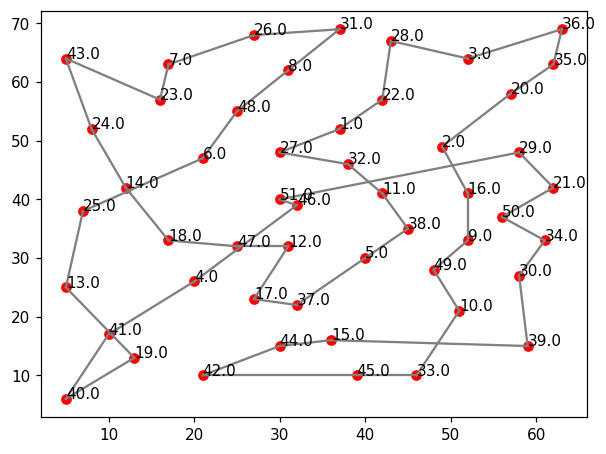

In [23]:
##################### Do not change ###########################
# initial values
POPULATION_SIZE = 2000
TOURNAMENT_SELECTION_SIZE = 4
MUTATION_RATE = 0.1
CROSSOVER_RATE = 0.9
TARGET = 450.0

cities = getCity()
firstPopulation, firstFitest = selectPopulation(cities, POPULATION_SIZE)
answer, genNumber = geneticAlgorithm(
    firstPopulation,
    len(cities),
    TOURNAMENT_SELECTION_SIZE,
    MUTATION_RATE,
    CROSSOVER_RATE,
    TARGET,
)

print(50*"-")
print("Generation: " + str(genNumber))
print("Fittest chromosome distance before training: " + str(firstFitest[0]))
print("Fittest chromosome distance after training: " + str(answer[0]))
print("Target distance: " + str(TARGET))
print(50*"-")

drawMap(cities, answer)
##################### Do not change ###########################

## Reproducible experiment summary

The TSP objective here is the sum of **unrounded Euclidean distances** around a closed tour. No claim about a TSPLIB rounded-distance optimum is made. The genetic algorithm uses tournament selection, order-preserving prefix crossover, swap mutation and two-individual elitism. The fixed assignment settings are 2,000 individuals and at most 200 generations, with target distance 450. A result that misses this target is still reported as such.


In [24]:
maze_summary = []
for name, search in [('DFS', dfs), ('BFS', bfs), ('A*', a_star)]:
    path, expanded = search(maze, maze.start, maze.goal)
    assert path and path[0] == maze.start and path[-1] == maze.goal
    assert all(b in maze.get_neighbors(a) for a, b in zip(path, path[1:]))
    maze_summary.append({'algorithm': name, 'moves': len(path) - 1,
                         'expanded_nodes': expanded, 'reached_goal': True})
for row in maze_summary:
    print(row)

restart_successes = 0
for seed in range(100):
    random.seed(seed)
    path = hill_climbing_with_restart_random_move(maze, maze.start, maze.goal, p=0.2)
    restart_successes += bool(path and path[-1] == maze.goal)
print(f'Randomized maze search: {restart_successes}/100 successes '
      '(seeds 0..99, 20 attempts each, p=0.2).')

reference_xs = np.linspace(-2, 2, 100001)
reference_index = int(np.argmin(f(reference_xs)))
reference_minimum = {'x': float(reference_xs[reference_index]),
                     'f_x': float(f(reference_xs[reference_index]))}
print('Dense-grid reference:', reference_minimum)
for row in one_dimensional_results:
    print(row)

assert len(answer[1]) == len(cities) and sorted(answer[1]) == sorted(cities)
tsp_summary = {'seed': SEED, 'cities': len(cities), 'generations': genNumber,
               'initial_best_distance': float(firstFitest[0]),
               'final_best_distance': float(answer[0]), 'target': TARGET,
               'target_reached': bool(answer[0] < TARGET),
               'improvement_percent': 100 * (firstFitest[0] - answer[0]) / firstFitest[0]}
print('TSP:', tsp_summary)


{'algorithm': 'DFS', 'moves': 112, 'expanded_nodes': 205, 'reached_goal': True}
{'algorithm': 'BFS', 'moves': 38, 'expanded_nodes': 161, 'reached_goal': True}
{'algorithm': 'A*', 'moves': 38, 'expanded_nodes': 55, 'reached_goal': True}
Randomized maze search: 51/100 successes (seeds 0..99, 20 attempts each, p=0.2).
Dense-grid reference: {'x': 1.5455200000000002, 'f_x': -1.3624007391034767}
{'run': 1, 'x': 1.550869623057177, 'f_x': -1.3622634610392712}
{'run': 2, 'x': 1.5549530170437356, 'f_x': -1.361974111909261}
{'run': 3, 'x': 1.5509242403843473, 'f_x': -1.3622606455180768}
{'run': 4, 'x': 1.5419755291821802, 'f_x': -1.3623407659960554}
{'run': 5, 'x': 1.5585895350138044, 'f_x': -1.361581821898982}
{'run': 6, 'x': 1.5411010559870388, 'f_x': -1.3623074824370267}
{'run': 7, 'x': 1.5612833074004027, 'f_x': -1.361209434108979}
{'run': 8, 'x': 1.5309166138278254, 'f_x': -1.361381696820717}
{'run': 9, 'x': 1.5331879598845106, 'f_x': -1.3616739729543317}
{'run': 10, 'x': 1.5613205067593239,